In [1]:
import salvus.namespace as sn
from salvus.material._details import material as md
from material_ela_constants.Elastic_Material import * 


# Directories in Windows
PROJECT_DIR_WIN = '/mnt/f/Salvus_project/elastic_model/anisotropic/Project'
DATA_DIR_WIN = '/mnt/f/Salvus_project/elastic_model/anisotropic/data'
IMAGE_DIR_WIN = '/mnt/f/Salvus_project/elastic_model/anisotropic/image'

# all figures of this notebook go to <image>/orientation_plot
from pathlib import Path
FIG_DIR = Path(IMAGE_DIR_WIN, 'orientation_plot')
FIG_DIR.mkdir(parents=True, exist_ok=True)



   ┌────────────────────────────────────────────────────────────────────────────────────┐
   │                                                                                    │
   │   Salvus update available!                                                         │
   │                                                                                    │
   │   2026.5.0 → 2026.10.0                                                             │
   │                                                                                    │
   │   See https://docs.mondaic.com/updates/changelog                                   │
   │   for a list of changes and new features.                                          │
   │                                                                                    │
   │   To upgrade, please first make sure that your python environment is up to date:   │
   │                                                                                    │
   │   ht

--> Server: 'https://l.mondaic.com/licensing_server', User: 'bristol.support', Group: 'UniversityOfBristol'.
--> Negotiating 1 license instance(s) for 'SalvusMesh' [license version 1.0.0] for 1 seconds ...
--> Success! [Total duration: 0.32 seconds]


In [2]:
matl = Austenite()
material_unoriented = sn.material.elastic.hexagonal.TensorComponents.from_params(**matl.VTI_parameters())
from salvus.material._details import material as md
# Define a default orientation for comparison
orientation_of_grains_default = sn.material.orientation.ClockwiseAngle.from_params(angle_in_degrees=0)

# Convert the unoriented material with default orientation to solver form for 2D simulations
matl_background = md.to_solver_form(material_unoriented.with_orientation(orientation_of_grains_default), ndim=2)


In [3]:
material_unoriented

salvus.material.elastic.hexagonal.TensorComponents

In [4]:
orientation_angle = sn.material.orientation.ClockwiseAngle.from_params(angle_in_degrees=np.rad2deg(np.pi/6))

matl_orientated = md.to_solver_form(material_unoriented.with_orientation(orientation_angle), ndim=2)
matl_orientated

Field,Type,Value (or range)
RHO,constant,8.1e+03
C11,constant,2.5e+11
C12,constant,1.2e+11
C13,constant,2.5e+10
C22,constant,2.8e+11
C23,constant,-5e+09
C33,constant,5.7e+10


salvus.material.elastic.monoclinic._TensorComponents2D

In [5]:
np.set_printoptions(
    threshold=np.inf,   # show entire array, no summarization
    linewidth=200,      # prevent line wrapping
    suppress=False,     # set to True if you don't want scientific notation
    precision=5          # number of digits after the decimal
)
matl.rotated_tensor(np.pi/6, dim=3)


array([[ 2.54519e+11,  6.32500e+09,  1.18506e+11,  0.00000e+00,  2.49307e+10,  0.00000e+00],
       [ 6.32500e+09,  2.17100e+11,  9.83750e+10,  0.00000e+00,  7.97176e+10,  0.00000e+00],
       [ 1.18506e+11,  9.83750e+10,  2.77569e+11,  0.00000e+00, -4.96882e+09,  0.00000e+00],
       [ 0.00000e+00,  0.00000e+00,  0.00000e+00,  9.39000e+10,  0.00000e+00, -1.99186e+10],
       [ 2.49307e+10,  7.97176e+10, -4.96882e+09,  0.00000e+00,  5.65062e+10,  0.00000e+00],
       [ 0.00000e+00,  0.00000e+00,  0.00000e+00, -1.99186e+10,  0.00000e+00,  1.16900e+11]])

In [6]:
matl.rotated_tensor(np.pi/6, dim=2)


array([[ 2.54519e+11,  1.18506e+11,  2.49307e+10],
       [ 1.18506e+11,  2.77569e+11, -4.96882e+09],
       [ 2.49307e+10, -4.96882e+09,  5.65062e+10]])

In [7]:
matl.C11

217100000000.0

In [8]:
import numpy as np

# example: VTI stiffness in material/principal axes (6x6 Voigt ordering [11,22,33,23,13,12])
C = matl.tensor()
# fill C with your VTI values:
# C[0,0]=C11; C[0,1]=C12; C[0,2]=C13; C[1,1]=C11; C[2,2]=C33...
# C[3,3]=C44; C[4,4]=C44; C[5,5]=C66

theta = np.pi/4   # tilt angle in radians
c = np.cos(theta); s = np.sin(theta)

L = np.array([
    [c*c, 0,   s*s, 0,     2*c*s, 0],
    [0,   1,   0,   0,     0,     0],
    [s*s, 0,   c*c, 0,    -2*c*s, 0],
    [0,   0,   0,   c,     0,    -s],
    [-c*s,0,   c*s, 0,  c*c - s*s, 0],
    [0,   0,   0,   s,     0,     c]
], dtype=float)

C_rot = L.dot(C).dot(L.T)   # rotated stiffness in global axes

# Extract 2D xz plane (Voigt indices 0->xx, 2->zz, 4->xz)
idx = [0, 2, 4]
C2D = C_rot[np.ix_(idx, idx)]

# Extract effective constants (Voigt order [11,22,33,23,13,12])
C11 = C_rot[0,0]
C12 = C_rot[0,1]
C13 = C_rot[0,2]
C22 = C_rot[1,1]
C23 = C_rot[1,2]
C33 = C_rot[2,2]
C44 = C_rot[3,3]   # corresponds to shear yz
C55 = C_rot[4,4]   # corresponds to shear xz
C66 = C_rot[5,5]   # corresponds to shear xy

print("Rotated stiffness constants (Voigt notation):")
print(f"C11 = {C11:.4e}")
print(f"C12 = {C12:.4e}")
print(f"C13 = {C13:.4e}")
print(f"C22 = {C22:.4e}")
print(f"C23 = {C23:.4e}")
print(f"C33 = {C33:.4e}")
print(f"C44 = {C44:.4e}")
print(f"C55 = {C55:.4e}")
print(f"C66 = {C66:.4e}")

print("\nC2D (xx, zz, xz):\n", C2D)


Rotated stiffness constants (Voigt notation):
C11 = 2.7468e+11
C12 = 5.2350e+10
C13 = 1.0988e+11
C22 = 2.1710e+11
C23 = 5.2350e+10
C33 = 2.7468e+11
C44 = 1.0540e+11
C55 = 4.7875e+10
C66 = 1.0540e+11

C2D (xx, zz, xz):
 [[2.74675e+11 1.09875e+11 1.15250e+10]
 [1.09875e+11 2.74675e+11 1.15250e+10]
 [1.15250e+10 1.15250e+10 4.78750e+10]]


In [9]:
import numpy as np

def rotated_stiffness(matl, theta_rad):
    """
    Compute rotated stiffness components C^R_ij from given stiffnesses and rotation angle.
    
    Parameters
    ----------
    C11, C13, C33, C55 : float
        Original stiffness coefficients.
    theta_deg : float
        Rotation angle in degrees.
        
    Returns
    -------
    dict
        Dictionary containing C^R_11, C^R_13, C^R_15, C^R_33, C^R_35, C^R_55.
    """
    C11 = matl.C11
    C13 = matl.C13
    C33 = matl.C33
    C55 = matl.C55
    θ = theta_rad
        
    alpha = C11 - 2*C13 + C33 - 4*C55
    beta = 3*C11 + 2*C13 + 3*C33 + 4*C55
    gamma = C11 - C33

    CR11 = (1/8) * (beta + 4*gamma*np.cos(2*θ) + alpha*np.cos(4*θ))
    CR13 = (1/8) * alpha*(1 - np.cos(4*θ)) + C13
    CR15 = (-1/8) * (2*gamma * np.sin(2*θ) + alpha*np.sin(4*θ))
    CR33 = (1/8) * (beta - 4*gamma*np.cos(2*θ) + alpha*np.cos(4*θ))
    CR35 = (-1/8) * (2*gamma * np.sin(2*θ) - alpha*np.sin(4*θ))
    CR55 = (1/8) * alpha*(1 - np.cos(4*θ)) + C55
    
    return {
        "C^R_11": CR11,
        "C^R_13": CR13,
        "C^R_15": CR15,
        "C^R_33": CR33,
        "C^R_35": CR35,
        "C^R_55": CR55
    }

# Example usage:
C = rotated_stiffness(matl, theta_rad=np.pi/8)
for k, v in C.items():
    print(f"{k} = {v:.3e}")


C^R_11 = 2.411e+11
C^R_13 = 1.271e+11
C^R_15 = 2.541e+10
C^R_33 = 2.737e+11
C^R_35 = -9.113e+09
C^R_55 = 6.514e+10


In [10]:
matl.rotated_tensor(np.pi/6, dim=2)


array([[ 2.54519e+11,  1.18506e+11,  2.49307e+10],
       [ 1.18506e+11,  2.77569e+11, -4.96882e+09],
       [ 2.49307e+10, -4.96882e+09,  5.65062e+10]])

In [11]:
matl.rotated_tensor(0, dim=2)


array([[2.171e+11, 1.444e+11, 0.000e+00],
       [1.444e+11, 2.632e+11, 0.000e+00],
       [0.000e+00, 0.000e+00, 8.240e+10]])

In [12]:
orientation_angle = sn.material.orientation.ClockwiseAngle.from_params(angle_in_degrees=np.rad2deg(np.pi/6))

matl_orientated = md.to_solver_form(material_unoriented.with_orientation(orientation_angle), ndim=2)
matl_orientated

Field,Type,Value (or range)
RHO,constant,8.1e+03
C11,constant,2.5e+11
C12,constant,1.2e+11
C13,constant,2.5e+10
C22,constant,2.8e+11
C23,constant,-5e+09
C33,constant,5.7e+10


salvus.material.elastic.monoclinic._TensorComponents2D

Saved /mnt/f/Salvus_project/elastic_model/anisotropic/image/orientation_plot/SH_wave_velocity_polar_plot.png


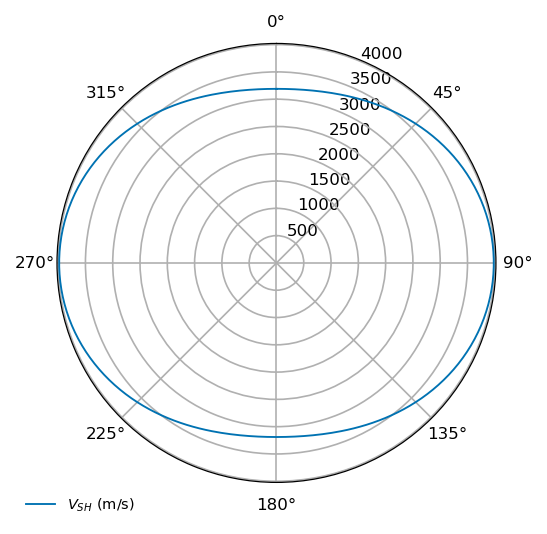

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from my_code.plot_style import apply_paper_style, save_paper_figure, SINGLE_COL, C_SYN

apply_paper_style()
theta = np.linspace(0 , 360, 361)
theta_deg = np.deg2rad(theta)
C44 = matl.C44 + np.sin(theta_deg) ** 2 * (matl.C66 - matl.C44)

Vsh = np.sqrt(C44 / matl.RHO)

fig = plt.figure(figsize=(SINGLE_COL, SINGLE_COL))
ax = fig.add_subplot(111, polar=True)
ax.set_theta_zero_location('N')   # 0 deg at the top (+z)
ax.set_theta_direction(-1)        # clockwise, as the orientation angle
ax.plot(theta_deg, Vsh, color=C_SYN, lw=0.9, label=r'$V_{SH}$ (m/s)')
ax.legend(loc='lower left', bbox_to_anchor=(-0.1, -0.1), frameon=False)
fig.tight_layout(pad=0.3)
save_paper_figure(fig, Path(FIG_DIR, 'SH_wave_velocity_polar_plot'))

Saved /mnt/f/Salvus_project/elastic_model/anisotropic/image/orientation_plot/SH_wave_slowness_polar_plot.png


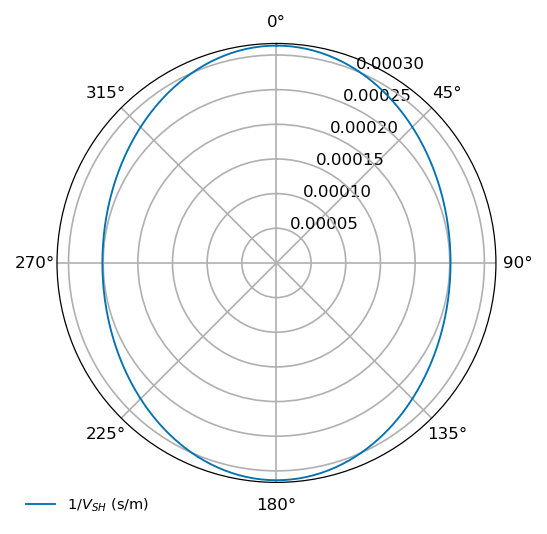

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from my_code.plot_style import apply_paper_style, save_paper_figure, SINGLE_COL, C_SYN

apply_paper_style()
theta = np.linspace(0 , 360, 361)
theta_deg = np.deg2rad(theta)
C44 = matl.C44 + np.sin(theta_deg) ** 2 * (matl.C66 - matl.C44)

Vsh = 1/np.sqrt(C44 / matl.RHO)

fig = plt.figure(figsize=(SINGLE_COL, SINGLE_COL))
ax = fig.add_subplot(111, polar=True)
ax.set_theta_zero_location('N')   # 0 deg at the top (+z)
ax.set_theta_direction(-1)        # clockwise, as the orientation angle
ax.plot(theta_deg, Vsh, color=C_SYN, lw=0.9, label=r'$1/V_{SH}$ (s/m)')
ax.legend(loc='lower left', bbox_to_anchor=(-0.1, -0.1), frameon=False)
fig.tight_layout(pad=0.3)
save_paper_figure(fig, Path(FIG_DIR, 'SH_wave_slowness_polar_plot'))

qP  5177-5864 m/s,  qSV 2414-3189 m/s


Saved /mnt/f/Salvus_project/elastic_model/anisotropic/image/orientation_plot/qP_qSV_phase_velocity_polar_plot_colour.png


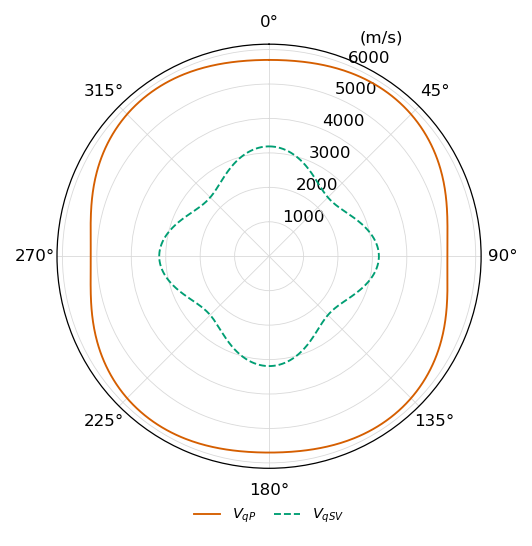

Saved /mnt/f/Salvus_project/elastic_model/anisotropic/image/orientation_plot/qP_qSV_phase_velocity_polar_plot_grey.png


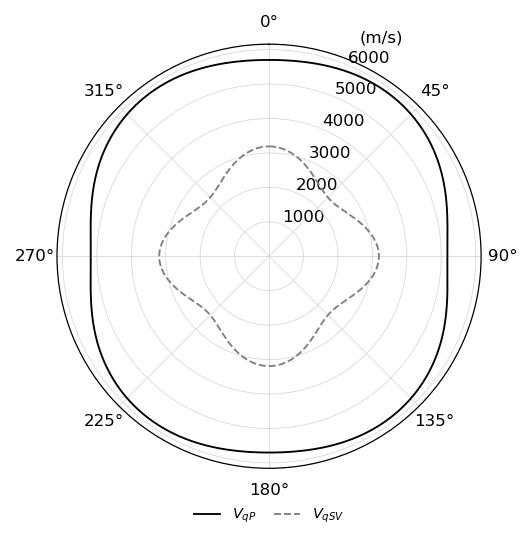

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from my_code.plot_style import apply_paper_style, save_paper_figure, SINGLE_COL, GRID_KW

# qP and qSV phase velocities in the x-z plane of the unrotated austenite (symmetry axis along +z):
# Christoffel matrix for the propagation direction n = (sin phi, cos phi), phi clockwise from +z,
#   G = [[C11 n_x^2 + C55 n_z^2, (C13 + C55) n_x n_z], [(C13 + C55) n_x n_z, C55 n_x^2 + C33 n_z^2]] / rho
# qP = sqrt(largest eigenvalue), qSV = sqrt(smallest). A grain rotated by theta rotates the curves by theta.
# Two colour options (line styles differ in both): Okabe-Ito colour (colour-blind safe) and greyscale.
apply_paper_style()
COLOUR_OPTIONS = {'colour': ('#D55E00', '#009E73'),       # vermilion qP, green qSV (as the original)
                  'grey':   ('k', '0.5')}                 # black qP, grey qSV (greyscale print)

phi = np.deg2rad(np.linspace(0, 360, 721))
nx, nz = np.sin(phi), np.cos(phi)
C55 = matl.C44
G11 = matl.C11 * nx**2 + C55 * nz**2
G33 = C55 * nx**2 + matl.C33 * nz**2
G13 = (matl.C13 + C55) * nx * nz
mean, half = 0.5 * (G11 + G33), np.sqrt(0.25 * (G11 - G33)**2 + G13**2)
v_qP  = np.sqrt((mean + half) / matl.RHO)
v_qSV = np.sqrt((mean - half) / matl.RHO)
print(f"qP  {v_qP.min():.0f}-{v_qP.max():.0f} m/s,  qSV {v_qSV.min():.0f}-{v_qSV.max():.0f} m/s")


def velocity_polar(curves, name):
    """Single-column polar plot of phase velocities; curves = [(v, colour, linestyle, label), ...]."""
    fig = plt.figure(figsize=(SINGLE_COL, SINGLE_COL))
    ax = fig.add_subplot(111, polar=True)
    ax.set_theta_zero_location('N')   # 0 deg at the top (+z, symmetry axis)
    ax.set_theta_direction(-1)        # clockwise, as the orientation angle
    for v, color, ls, label in curves:
        ax.plot(phi, v, color=color, lw=0.9, ls=ls, label=label)
    ax.set_ylim(0, 1.05 * v_qP.max())
    ax.set_rlabel_position(22.5)
    ax.text(np.deg2rad(22.5), 1.17 * v_qP.max(), '(m/s)', ha='left', va='center')   # radial unit
    ax.grid(True, **GRID_KW)          # light grid: the curves stand out
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.06), ncol=len(curves), frameon=False,
              handlelength=1.8, columnspacing=1.2)
    fig.tight_layout(pad=0.3)
    save_paper_figure(fig, Path(FIG_DIR, name))
    plt.show()


for option, (c_qp, c_qsv) in COLOUR_OPTIONS.items():
    velocity_polar([(v_qP, c_qp, '-', r'$V_{qP}$'), (v_qSV, c_qsv, '--', r'$V_{qSV}$')],
                   f'qP_qSV_phase_velocity_polar_plot_{option}')

In [16]:
# 

Saved /mnt/f/Salvus_project/elastic_model/anisotropic/image/orientation_plot/angular_dependence_dC_dtheta.png


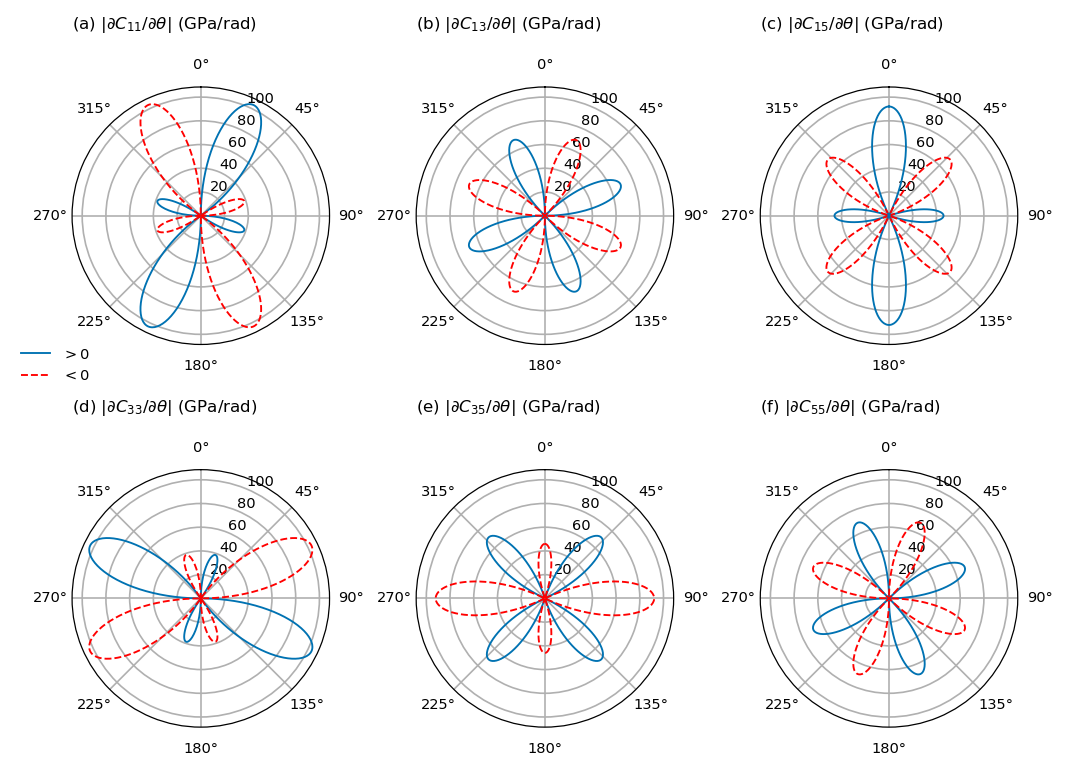

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from my_code.plot_style import apply_paper_style, save_paper_figure, DOUBLE_COL, C_SYN

# Derivative of the rotated x-z plane stiffness w.r.t. the orientation angle theta (ClockwiseAngle,
# symmetry axis clockwise from +z), 3D Voigt indices of the x-z plane (1 = xx, 3 = zz, 5 = xz):
#   alpha = C11 - 2 C13 + C33 - 4 C55,  gamma = C11 - C33   (unrotated constants, C55 = C44)
#   dC11/dt = -(alpha sin4t + 2 gamma sin2t)/2     dC13/dt = alpha sin4t / 2
#   dC15/dt = -(gamma cos2t + alpha cos4t)/2       dC33/dt = -(alpha sin4t - 2 gamma sin2t)/2
#   dC35/dt = -(gamma cos2t - alpha cos4t)/2       dC55/dt = alpha sin4t / 2
# (= dC_dtheta of the FWI scripts; Salvus names C11, C12, C13, C22, C23, C33)
apply_paper_style()
theta = np.deg2rad(np.linspace(0, 360, 721))
alpha = matl.C11 - 2 * matl.C13 + matl.C33 - 4 * matl.C44
gamma = matl.C11 - matl.C33
s2, c2, s4, c4 = np.sin(2 * theta), np.cos(2 * theta), np.sin(4 * theta), np.cos(4 * theta)
dC = {
    '11': -0.5 * (alpha * s4 + 2 * gamma * s2),
    '13':  0.5 * alpha * s4,
    '15': -0.5 * (gamma * c2 + alpha * c4),
    '33': -0.5 * (alpha * s4 - 2 * gamma * s2),
    '35': -0.5 * (gamma * c2 - alpha * c4),
    '55':  0.5 * alpha * s4,
}
r_max = max(np.abs(d).max() for d in dC.values()) / 1e9          # common radial scale [GPa/rad]

# polar |dC/dtheta|: solid where dC/dtheta > 0, dashed where < 0
fig, axes = plt.subplots(2, 3, figsize=(DOUBLE_COL, 5.0), subplot_kw={'polar': True},
                         layout='constrained')
for k, (ax, (ij, d)) in enumerate(zip(axes.ravel(), dC.items())):
    d = d / 1e9
    ax.set_theta_zero_location('N')   # 0 deg at the top (+z)
    ax.set_theta_direction(-1)        # clockwise, as the orientation angle
    ax.plot(theta, np.where(d >= 0, d, np.nan), color=C_SYN, lw=0.9, label=r'$> 0$')
    ax.plot(theta, np.where(d < 0, -d, np.nan), color='red', lw=0.9, ls='--', label=r'$< 0$')
    ax.set_ylim(0, 1.05 * r_max)
    ax.set_rlabel_position(22.5)
    ax.tick_params(labelsize=7)
    ax.set_title(rf'({"abcdef"[k]}) $|\partial C_{{{ij}}}/\partial\theta|$ (GPa/rad)', loc='left', pad=14)
axes[0, 0].legend(loc='lower left', bbox_to_anchor=(-0.25, -0.2), frameon=False)
save_paper_figure(fig, Path(FIG_DIR, 'angular_dependence_dC_dtheta'))
plt.show()